# Práctica 5: IA Explicable · Solución

Adaptación del notebook de la clase de teoría (problema Iris) al problema `breast-cancer-wisconsin.data`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import train_test_split
from lime import lime_tabular
import shap

c:\Users\uo282000\Desktop\Inteligencia de Negocio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Datos y modelo

In [3]:
data = pd.read_csv('./material/bsd/breast-cancer-wisconsin.data', header=None)
data.columns=['Id number','Clump Thickness','Uniformity of Cell Size','Uniformity of Cell Shape','Marginal Adhesion','Single Epithelial Cell Size','Bare Nuclei','Bland Chromatin','Normal Nucleoli','Mitoses','Class']
data2 = data.apply(pd.to_numeric, errors='coerce') # los valores '?' pasan a NaN
data = data2.dropna()                               # se eliminan las 16 muestras incompletas

# El identificador de la muestra no es una variable del problema
del data['Id number']

# Clases: 0 benigno, 1 maligno
data.loc[:,"Class"] = data.Class.replace(2,0)
data.loc[:,"Class"] = data.Class.replace(4,1)

data.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1.0,3,1,1,0
1,5,4,4,5,7,10.0,3,2,1,0
2,3,1,1,1,2,2.0,3,1,1,0
3,6,8,8,1,3,4.0,3,7,1,0
4,4,1,1,3,2,1.0,3,1,1,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(data.iloc[:, :9],  # las nueve características
                                                    data.iloc[:, 9],   # el diagnóstico
                                                    test_size=0.2,
                                                    random_state = 123)

clf = RandomForestClassifier(random_state=0)
clf.fit(X_train.values, y_train)
print(f"Score: {clf.score(X_test.values, y_test)}")

Score: 0.9781021897810219


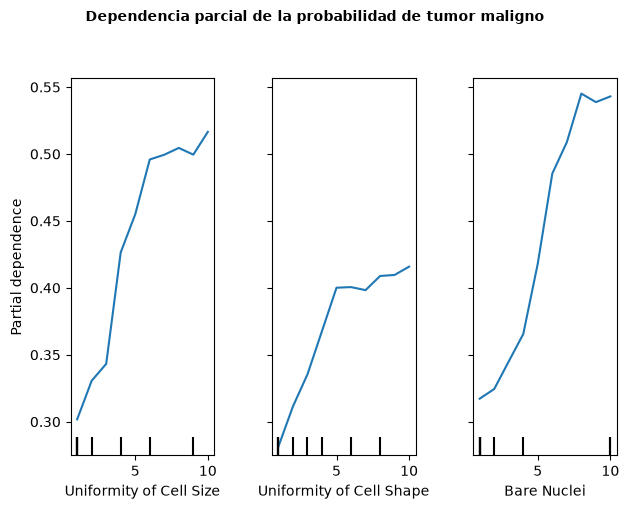

In [6]:
variables = ["Uniformity of Cell Size", "Uniformity of Cell Shape", "Bare Nuclei"]

# Create the partial dependence display
pdp = PartialDependenceDisplay.from_estimator(clf, 
                                              X_train.astype(float).values, 
                                              features = variables, 
                                              feature_names= X_train.columns.tolist(),
                                              grid_resolution=30)

# Adjust the subplots spacing
pdp.figure_.subplots_adjust(wspace=0.4, hspace=0.4)

# Set the suptitle
plt.suptitle("Dependencia parcial de la probabilidad de tumor maligno", y=1.05, fontsize=10, fontweight='bold')

# Tighten the layout
plt.tight_layout()

In [7]:
X_test

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses
154,1,1,1,1,2,1.0,1,1,1
687,3,1,1,1,2,1.0,2,3,1
80,2,2,2,1,1,1.0,7,1,1
269,1,1,1,1,2,1.0,3,1,1
136,4,1,1,1,2,1.0,2,1,1
...,...,...,...,...,...,...,...,...,...
188,5,8,4,10,5,8.0,9,10,1
328,8,10,3,2,6,4.0,3,10,1
310,2,1,1,1,3,1.0,2,1,1
237,9,8,8,5,6,2.0,4,10,4


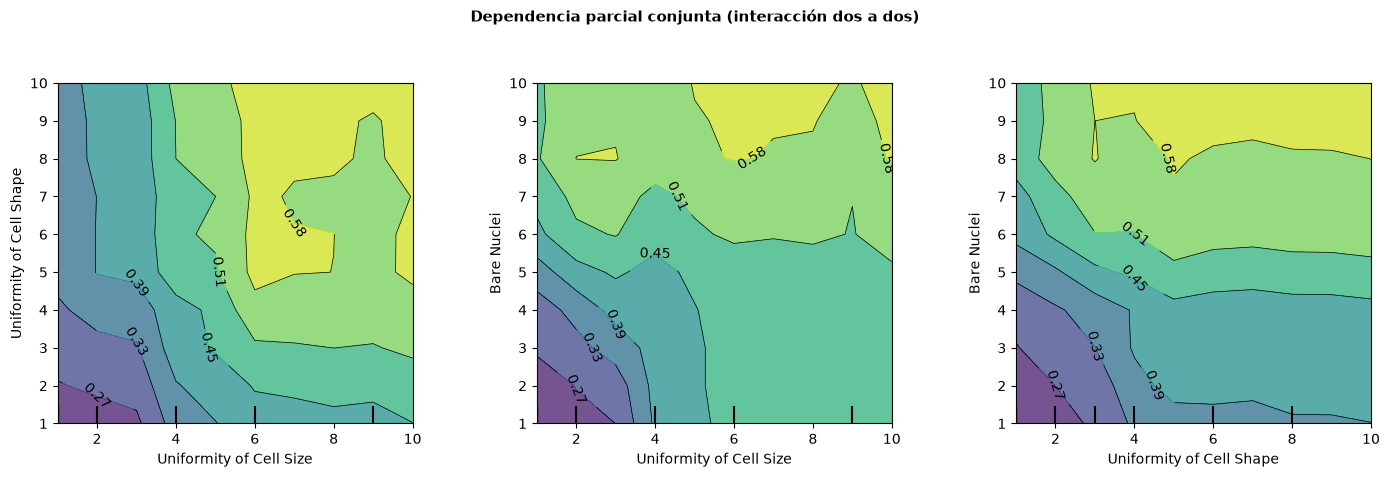

In [8]:
# %% 2. Gráfico de dependencia parcial (combinaciones dos a dos)
pares = [
    ("Uniformity of Cell Size", "Uniformity of Cell Shape"),
    ("Uniformity of Cell Size", "Bare Nuclei"),
    ("Uniformity of Cell Shape", "Bare Nuclei"),
]

pdp_2d = PartialDependenceDisplay.from_estimator(
    clf,
    X_train.values,
    features=pares,
    feature_names=X_train.columns.tolist(),
    grid_resolution=20,
)

pdp_2d.figure_.set_size_inches(14, 4.5)
pdp_2d.figure_.subplots_adjust(wspace=0.35)
plt.suptitle(
    "Dependencia parcial conjunta (interacción dos a dos)",
    y=1.05,
    fontsize=11,
    fontweight="bold",
)
plt.tight_layout()
plt.show()